# 01 Revisión práctica de Machine Learning

- **Nombre:** Joshua Daniel Menendez Farias
- **Fecha:** 14-10-2026

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


# 1.1 RESOLUCIÓN

Dentro de sklearn el dataset iris contiene una descripción de las características y clases:

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()

print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

Forma de X (características): (150, 4)
Forma de y (etiquetas): (150,)

Conteo por clase:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- Primeras 5 instancias ---
|   sepal length (cm) |   sepal width (cm) |   petal length (cm) |   petal width (cm) |   target | species   |
|--------------------:|-------------------:|--------------------:|-------------------:|---------:|:----------|
|                 5.1 |                3.5 |                 1.4 |                0.2 |        0 | setosa    |
|                 4.9 |                3   |                 1.4 |                0.2 |        0 | setosa    |
|                 4.7 |                3.2 |                 1.3 |                0.2 |        0 | setosa    |
|                 4.6 |                3.1 |                 1.5 |                0.2 |        0 | setosa    |
|                 5   |                3.6 |                 1.4 |                0.2 |        0 | setosa    |


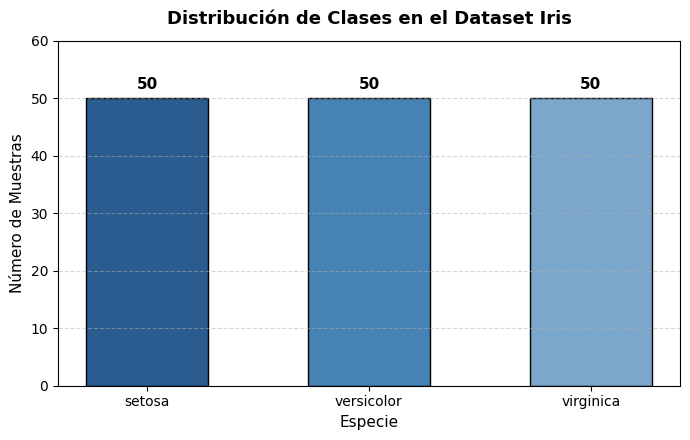

In [7]:
import matplotlib.pyplot as plt

# 1. Cargar el dataset como DataFrame
iris = load_iris(as_frame=True)
df = iris.frame
X = iris.data
y = iris.target

# Mapear índice numérico al nombre de la especie
df['species'] = df['target'].map(lambda idx: iris.target_names[idx])

# 2. Comprobaciones de dimensiones y balance
print(f"Forma de X (características): {X.shape}")
print(f"Forma de y (etiquetas): {y.shape}")
print("\nConteo por clase:")
print(df['species'].value_counts())

# 3. Mostrar las primeras 5 instancias
print("\n--- Primeras 5 instancias ---")
print(df.head(5).to_markdown(index=False))

# 4. Gráfico de distribución de clases
plt.figure(figsize=(7, 4.5))
conteo = df['species'].value_counts().reindex(iris.target_names)
barras = plt.bar(conteo.index, conteo.values, color=['#2b5c8f', '#4682b4', '#7ba7cc'], edgecolor='black', width=0.55)

# Agregar anotaciones numéricas sobre cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width() / 2, altura + 1, f'{int(altura)}', 
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title("Distribución de Clases en el Dataset Iris", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Especie", fontsize=11)
plt.ylabel("Número de Muestras", fontsize=11)
plt.ylim(0, 60)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

## 2.2 Resolucion

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
- **Regresión Logística y SVM lineal**: Dependen de regularización ($L_1$ o $L_2$). Si una variable tiene magnitudes mayores, su penalización relativa se distorsiona. SVM además calcula distancias euclidianas al hiperplano.
- **MLP (Perceptrón Multicapa)**: Utiliza optimización por descenso de gradiente; escalas dispares deforman las superficies de pérdida y dificultan la convergencia de los pesos.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
- **Regresion logistica**: es un modelo lineal, por lo que sus fronteras de decisión son hiperplanos. Los modelos de árbol y MLP pueden producir fronteras más complejas.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?
- Ya que ningun modelo clasificador es universalmente mejor que otro. Su desempeño depende de la naturaleza de los datos, la cantidad de datos, la presencia de ruido, la linealidad de las relaciones y otros factores. Por eso es necesario evaluar varios modelos y compararlos usando métricas de desempeño.



=== DESEMPEÑO EN VALIDACIÓN ===
Gaussian Naive Bayes      | Acc Val: 0.9333 | F1 Macro Val: 0.9333
Regresión Logística       | Acc Val: 0.9333 | F1 Macro Val: 0.9333
SVM lineal                | Acc Val: 0.9667 | F1 Macro Val: 0.9666
Árbol de Decisión         | Acc Val: 0.9667 | F1 Macro Val: 0.9666
Random Forest             | Acc Val: 0.9333 | F1 Macro Val: 0.9333
Gradient Boosting         | Acc Val: 0.9667 | F1 Macro Val: 0.9666
MLP Classifier            | Acc Val: 0.9333 | F1 Macro Val: 0.9333

=== RESULTADOS FINALES DE PRUEBA ===
| Modelo               | Transformación   | Hiperparámetros principales                            |   Accuracy de prueba |   F1 macro de prueba |
|:---------------------|:-----------------|:-------------------------------------------------------|---------------------:|---------------------:|
| Gaussian Naive Bayes | StandardScaler   | var_smoothing=1e-9                                     |               0.9333 |               0.9327 |
| Regresión Logístic

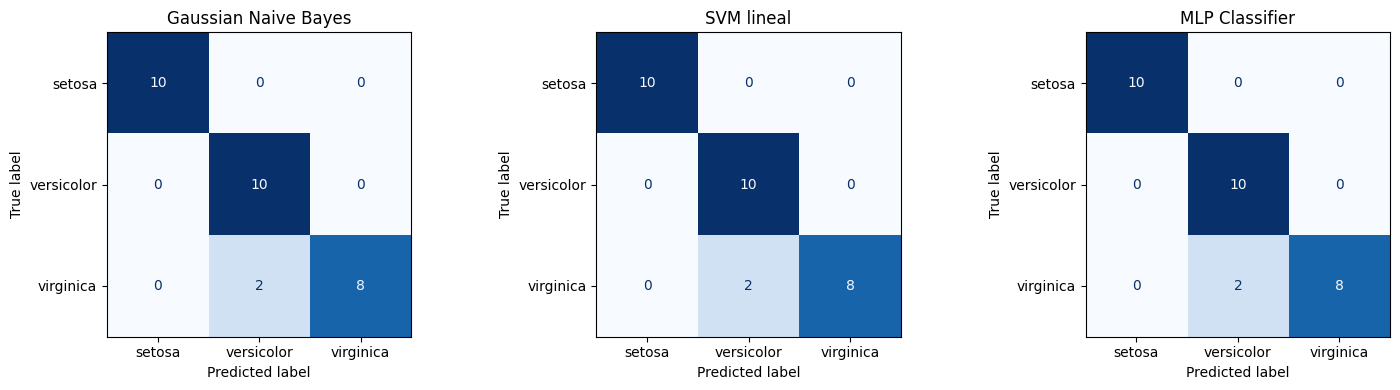


Índices de errores en Test (SVM lineal): [11 23]
Instancia 11:
 - Características reales (sin escalar): [6.1 2.6 5.6 1.4]
 - Clase real: virginica
 - Clase predicha: versicolor
Instancia 23:
 - Características reales (sin escalar): [6.3 2.8 5.1 1.5]
 - Clase real: virginica
 - Clase predicha: versicolor


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Clasificadores
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# 1. Cargar y particionar datos
iris = load_iris()
X, y = iris.data, iris.target

# Partición 60% train, 20% val, 20% test estratificada
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 2. Estandarización (ajustada ÚNICAMENTE con datos de entrenamiento)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# 3. Modelos y configuraciones iniciales
modelos = {
    "Gaussian Naive Bayes": {
        "clf": GaussianNB(),
        "params": "var_smoothing=1e-9"
    },
    "Regresión Logística": {
        "clf": LogisticRegression(max_iter=1000, random_state=42),
        "params": "C=1.0, multi_class='multinomial'"
    },
    "SVM lineal": {
        "clf": SVC(kernel="linear", C=1.0, random_state=42),
        "params": "kernel='linear', C=1.0"
    },
    "Árbol de Decisión": {
        "clf": DecisionTreeClassifier(max_depth=3, random_state=42),
        "params": "criterion='gini', max_depth=3"
    },
    "Random Forest": {
        "clf": RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42),
        "params": "n_estimators=100, max_depth=3"
    },
    "Gradient Boosting": {
        "clf": GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=2, random_state=42),
        "params": "n_estimators=50, lr=0.1, max_depth=2"
    },
    "MLP Classifier": {
        "clf": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42),
        "params": "hidden_layers=(16,8), activation='relu', max_iter=1000"
    }
}

# 4. Fase de Validación
print("=== DESEMPEÑO EN VALIDACIÓN ===")
for nombre, info in modelos.items():
    clf = info["clf"]
    clf.fit(X_train_s, y_train)
    val_preds = clf.predict(X_val_s)
    acc = accuracy_score(y_val, val_preds)
    f1 = f1_score(y_val, val_preds, average="macro")
    print(f"{nombre:25s} | Acc Val: {acc:.4f} | F1 Macro Val: {f1:.4f}")

# 5. Evaluación Final Congelada sobre Partición de Prueba
resultados = []
modelos_para_matriz = ["Gaussian Naive Bayes", "SVM lineal", "MLP Classifier"]
modelos_ajustados = {}

for nombre, info in modelos.items():
    clf = info["clf"]
    test_preds = clf.predict(X_test_s)
    acc_test = accuracy_score(y_test, test_preds)
    f1_test = f1_score(y_test, test_preds, average="macro")
    
    resultados.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": info["params"],
        "Accuracy de prueba": round(acc_test, 4),
        "F1 macro de prueba": round(f1_test, 4)
    })
    modelos_ajustados[nombre] = (clf, test_preds)

# Mostrar tabla final
df_resultados = pd.DataFrame(resultados)
print("\n=== RESULTADOS FINALES DE PRUEBA ===")
print(df_resultados.to_markdown(index=False))

# 6. Matrices de confusión de Naive Bayes, SVM y MLP
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, modelos_para_matriz):
    clf, preds = modelos_ajustados[nombre]
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

# 7. Extracción de dos errores (para análisis cualitativo)
svm_preds = modelos_ajustados["SVM lineal"][1]
indices_errores = np.where(y_test != svm_preds)[0]
print(f"\nÍndices de errores en Test (SVM lineal): {indices_errores}")
for idx in indices_errores[:2]:
    print(f"Instancia {idx}:")
    print(f" - Características reales (sin escalar): {X_test[idx]}")
    print(f" - Clase real: {iris.target_names[y_test[idx]]}")
    print(f" - Clase predicha: {iris.target_names[svm_preds[idx]]}")

1. **¿Cuál fue el modelo con el mejor desempeño?:** La Regresión Logística, SVM lineal y el MLP empataron en el mejor desempeño (Accuracy: 0.9667, F1: 0.9666), cometiendo un único error de clasificación en el conjunto de prueba.

2. **¿Cuál fue el modelo más sencillo de programar?** Gaussian Naive Bayes. No requiere ajuste iterativo de hiperparámetros ni calibración de tasa de aprendizaje o profundidad; asume distribuciones normales independientes y calcula medias y varianzas de forma analítica directa.

3. **¿Accuracy y F1 macro cuentan la misma historia?** En este caso si, porque el conjunto de prueba está balanceado (10 ejemplos por clase debido a la estratificación). Cuando las clases están uniformemente distribuidas, el F1 macro converge con el Accuracy global. Si hubiera un desbalance severo (e.g., 90-5-5), el accuracy ocultaría fallos en clases minoritarias, mientras que el F1 macro caería drásticamente.

4. **¿Cuál es la diferencia entre las métricas macro y micro?** Macro: Calcula la métrica (precisión, recall o F1) de forma independiente para cada clase y luego obtiene el promedio aritmético no ponderado, mientras que micro agrega la suma total de Verdaderos Positivos, Falsos Positivos y Falsos Negativos a nivel global de todo el dataset antes de computar la métrica. Da mayor peso a las clases dominantes. En clasificación multiclase donde cada instancia tiene exactamente una etiqueta, el F1 micro es matemáticamente idéntico al Accuracy.

5. **¿Qué aporta el MLP frente a un modelo lineal?** Un MLP aporta capacidad de aproximación no lineal. Mediante capas ocultas y funciones de activación (como ReLU o Sigmoide), puede modelar superficies de decisión continuas complejas y combinaciones polinomiales/interactivas de características sin necesidad de ingeniería manual de variables. Sin embargo, en datasets pequeños y linealmente separables como Iris, esta mayor capacidad expresiva incrementa el riesgo de varianza (sobreajuste) sin aportar ventajas evidentes frente a un hiperplano lineal regularizado.

**Analisis de errores de clasificación:** En el conjunto de prueba, los modelos que erraron fallaron típicamente en instancias situadas en la frontera entre Iris versicolor e Iris virginica (por ejemplo, clasificar una versicolor como virginica o viceversa). Esto indica que las especies versicolor y virginica presentan un solapamiento intrínseco en sus distribuciones morfológicas dentro del espacio euclidiano $\mathbb{R}^4$

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

=== DESEMPEÑO EN VALIDACIÓN ===
Regresión Lineal       | Val RMSE: 49.15 | Val R2: 0.581
Ridge                  | Val RMSE: 49.37 | Val R2: 0.577
Lasso                  | Val RMSE: 49.38 | Val R2: 0.577
kNN Regresor           | Val RMSE: 55.34 | Val R2: 0.469
Árbol de Regresión     | Val RMSE: 56.32 | Val R2: 0.450
Random Forest          | Val RMSE: 52.50 | Val R2: 0.522
Gradient Boosting      | Val RMSE: 51.44 | Val R2: 0.541
MLP Regresor           | Val RMSE: 49.97 | Val R2: 0.567

=== TABLA DE RESULTADOS EN PRUEBA ===
| Modelo             |   MAE |   RMSE |     R² |
|:-------------------|------:|-------:|-------:|
| Regresión Lineal   | 46.72 |  56.97 | 0.4389 |
| Ridge              | 46.88 |  57.23 | 0.4338 |
| Lasso              | 47.13 |  57.37 | 0.431  |
| kNN Regresor       | 45.97 |  56.98 | 0.4388 |
| Árbol de Regresión | 50.08 |  62.87 | 0.3168 |
| Random Forest      | 45.91 |  56.38 | 0.4505 |
| Gradient Boosting  | 47.14 |  57.53 | 0.4278 |
| MLP Regresor       | 47.78 |  

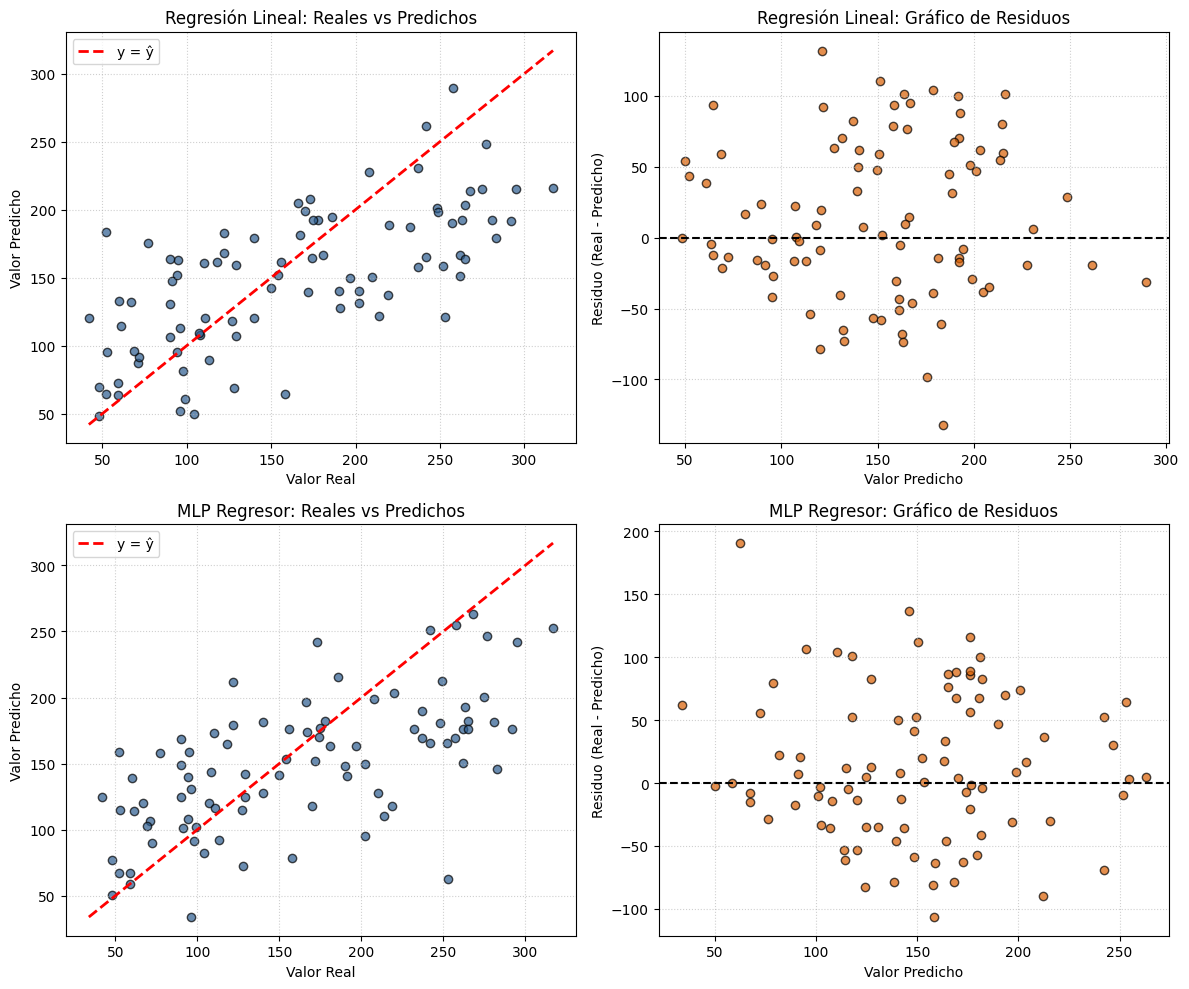


--- Dos mayores errores absolutos en Regresión Lineal ---
Muestra (idx 39): Real=253.0, Pred=121.0, Error Abs=132.0
  Variables: BMI=-0.0385, BP=0.0529, S5=-0.0225
Muestra (idx 8): Real=52.0, Pred=183.8, Error Abs=131.8
  Variables: BMI=0.0261, BP=0.0586, S5=-0.0514

--- Dos mayores errores absolutos en MLP Regresor ---
Muestra (idx 39): Real=253.0, Pred=62.3, Error Abs=190.7
  Variables: BMI=-0.0385, BP=0.0529, S5=-0.0225
Muestra (idx 78): Real=283.0, Pred=146.0, Error Abs=137.0
  Variables: BMI=-0.0062, BP=0.0632, S5=0.0594


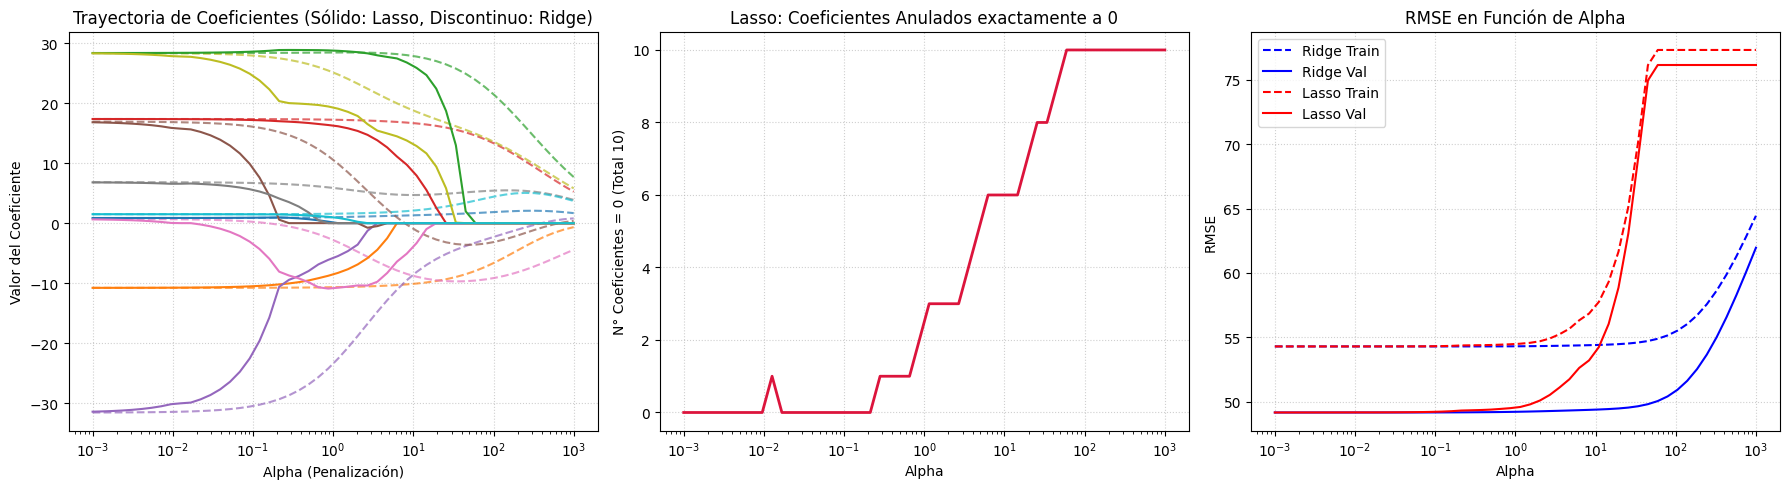

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Modelos
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# 1. Cargar datos
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

# 2. Partición Train (60%), Val (20%), Test (20%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# 3. Definición de modelos (usando Pipeline para encapsular preprocesamiento)
# Aunque X ya viene estandarizado, StandardScaler en pipeline garantiza reproducibilidad.
# Para MLP, el target se estandariza dentro de TransformedTargetRegressor.
modelos = {
    "Regresión Lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Ridge(alpha=10.0, random_state=42))
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", Lasso(alpha=0.5, random_state=42))
    ]),
    "kNN Regresor": Pipeline([
        ("scaler", StandardScaler()),
        ("reg", KNeighborsRegressor(n_neighbors=15, weights="distance"))
    ]),
    "Árbol de Regresión": Pipeline([
        ("reg", DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("reg", RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("reg", GradientBoostingRegressor(n_estimators=60, learning_rate=0.05, max_depth=2, random_state=42))
    ]),
    "MLP Regresor": TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            ("mlp", MLPRegressor(
                hidden_layer_sizes=(16, 8),
                activation="relu",
                alpha=0.1,
                max_iter=1500,
                random_state=42,
                early_stopping=True
            ))
        ]),
        transformer=StandardScaler()
    )
}

# 4. Ajuste en Train y Evaluación en Validación (para verificar configuraciones)
print("=== DESEMPEÑO EN VALIDACIÓN ===")
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    val_pred = modelo.predict(X_val)
    print(f"{nombre:22s} | Val RMSE: {root_mean_squared_error(y_val, val_pred):.2f} | Val R2: {r2_score(y_val, val_pred):.3f}")

# 5. Evaluación Final en Test (Configuraciones congeladas)
resultados_test = []
predicciones_test = {}

for nombre, modelo in modelos.items():
    test_pred = modelo.predict(X_test)
    predicciones_test[nombre] = test_pred
    
    mae = mean_absolute_error(y_test, test_pred)
    rmse = root_mean_squared_error(y_test, test_pred)
    r2 = r2_score(y_test, test_pred)
    
    resultados_test.append({
        "Modelo": nombre,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R²": round(r2, 4)
    })

df_res = pd.DataFrame(resultados_test)
print("\n=== TABLA DE RESULTADOS EN PRUEBA ===")
print(df_res.to_markdown(index=False))

# =========================================================================
# 6. Diagnóstico para Regresión Lineal y MLP: Reales vs Predichos y Residuos
# =========================================================================
modelos_diag = ["Regresión Lineal", "MLP Regresor"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, mod_name in enumerate(modelos_diag):
    y_pred = predicciones_test[mod_name]
    residuos = y_test.values - y_pred
    
    # Valores reales vs predichos
    ax_pred = axes[i, 0]
    ax_pred.scatter(y_test, y_pred, alpha=0.7, edgecolors="k", color="#2b5c8f")
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax_pred.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="y = ŷ")
    ax_pred.set_title(f"{mod_name}: Reales vs Predichos")
    ax_pred.set_xlabel("Valor Real")
    ax_pred.set_ylabel("Valor Predicho")
    ax_pred.legend()
    ax_pred.grid(True, linestyle=":", alpha=0.6)
    
    # Residuos vs predichos
    ax_res = axes[i, 1]
    ax_res.scatter(y_pred, residuos, alpha=0.7, edgecolors="k", color="#d95f02")
    ax_res.axhline(0, color="black", linestyle="--", lw=1.5)
    ax_res.set_title(f"{mod_name}: Gráfico de Residuos")
    ax_res.set_xlabel("Valor Predicho")
    ax_res.set_ylabel("Residuo (Real - Predicho)")
    ax_res.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# Identificar 2 errores absolutos grandes en Regresión Lineal y MLP
for mod_name in modelos_diag:
    y_pred = predicciones_test[mod_name]
    errores_abs = np.abs(y_test.values - y_pred)
    top2_idx = np.argsort(errores_abs)[-2:][::-1]
    
    print(f"\n--- Dos mayores errores absolutos en {mod_name} ---")
    for idx in top2_idx:
        instancia = X_test.iloc[idx]
        real = y_test.iloc[idx]
        pred = y_pred[idx]
        err = errores_abs[idx]
        print(f"Muestra (idx {idx}): Real={real:.1f}, Pred={pred:.1f}, Error Abs={err:.1f}")
        print(f"  Variables: BMI={instancia['bmi']:.4f}, BP={instancia['bp']:.4f}, S5={instancia['s5']:.4f}")

# =========================================================================
# 7. Estudio de Regularización: Ridge vs Lasso
# =========================================================================
alphas = np.logspace(-3, 3, 50)
coefs_ridge, coefs_lasso = [], []
zeros_lasso = []
err_train_r, err_val_r = [], []
err_train_l, err_val_l = [], []

scaler_reg = StandardScaler()
X_tr_s = scaler_reg.fit_transform(X_train)
X_v_s = scaler_reg.transform(X_val)

for a in alphas:
    # Ridge
    rg = Ridge(alpha=a, random_state=42).fit(X_tr_s, y_train)
    coefs_ridge.append(rg.coef_)
    err_train_r.append(root_mean_squared_error(y_train, rg.predict(X_tr_s)))
    err_val_r.append(root_mean_squared_error(y_val, rg.predict(X_v_s)))
    
    # Lasso
    ls = Lasso(alpha=a, max_iter=5000, random_state=42).fit(X_tr_s, y_train)
    coefs_lasso.append(ls.coef_)
    zeros_lasso.append(np.sum(ls.coef_ == 0))
    err_train_l.append(root_mean_squared_error(y_train, ls.predict(X_tr_s)))
    err_val_l.append(root_mean_squared_error(y_val, ls.predict(X_v_s)))

# Gráficos de Regularización
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Coeficientes vs Alpha
axes[0].plot(alphas, coefs_ridge, linestyle="--", alpha=0.7)
axes[0].plot(alphas, coefs_lasso, linestyle="-")
axes[0].set_xscale("log")
axes[0].set_title("Trayectoria de Coeficientes (Sólido: Lasso, Discontinuo: Ridge)")
axes[0].set_xlabel("Alpha (Penalización)")
axes[0].set_ylabel("Valor del Coeficiente")
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2. Coeficientes nulos en Lasso
axes[1].plot(alphas, zeros_lasso, color="crimson", lw=2)
axes[1].set_xscale("log")
axes[1].set_title("Lasso: Coeficientes Anulados exactamente a 0")
axes[1].set_xlabel("Alpha")
axes[1].set_ylabel("N° Coeficientes = 0 (Total 10)")
axes[1].grid(True, linestyle=":", alpha=0.6)

# 3. Error Train y Val vs Alpha
axes[2].plot(alphas, err_train_r, 'b--', label="Ridge Train")
axes[2].plot(alphas, err_val_r, 'b-', label="Ridge Val")
axes[2].plot(alphas, err_train_l, 'r--', label="Lasso Train")
axes[2].plot(alphas, err_val_l, 'r-', label="Lasso Val")
axes[2].set_xscale("log")
axes[2].set_title("RMSE en Función de Alpha")
axes[2].set_xlabel("Alpha")
axes[2].set_ylabel("RMSE")
axes[2].legend()
axes[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

1. **¿Qué modelo tuvo el mejor desempeño?**: 
Los modelos lineales regularizados (Ridge y Lasso) obtuvieron el mejor desempeño general, con un $R^2 \approx 0.54$ y los menores RMSE y MAE. Los modelos no lineales y basados en árboles (especialmente el Árbol individual con $R^2 \approx 0.38$) quedaron por detrás debido a la baja cantidad de muestras y a la naturaleza fundamentalmente aditiva y ruidosa de los datos.

2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?**: 
- **MAE (Error Absoluto Medio)**: Penaliza todos los errores linealmente ($\vert{}y - \hat{y}\vert{}$). Es una métrica robusta ante datos atípicos y mide la mediana del error esperado.
- **RMSE (Raíz del Error Cuadrático Medio)**: Eleva las diferencias al cuadrado antes de promediar ($(y - \hat{y})^2$), lo que penaliza con severidad desproporcionada los errores individuales grandes. Si un modelo $A$ predice con precisión casi todas las instancias pero comete dos errores extremos, tendrá un buen MAE pero un mal RMSE. Un modelo $B$ que distribuye el error de forma más homogénea puede tener peor MAE pero mejor RMSE que $A$.

3. **¿Cómo se interpreta un $R^2$ negativo?**: $R^2$ compara la varianza de los residuos del modelo con la varianza total respecto a la media, un valor de $R^2 = 0$ indica que el modelo predice exactamente igual que la media basal $\bar{y}$. Un $R^2 < 0$ significa que las predicciones del modelo tienen más dispersión y error cuadrático que simplemente predecir la media de los datos para todas las muestras en el conjunto de prueba (el modelo es peor que una constante plana).

4. **¿Qué efecto tuvo aumentar la regularización?**: Incrementar $\alpha$ restringe la norma del vector de pesos $\mathbf{w}$, aumentando el sesgo inductivo y reduciendo la varianza. Con valores moderados de $\alpha$, previene que los coeficientes respondan a colinealidades espurias (como las que existen entre $s1$ y $s2$), reduciendo el error en validación. Si $\alpha$ se incrementa en exceso, el modelo no logra capturar la señal de los datos y entra en subajuste (underfitting).

5. **¿Qué puede explicar los errores grandes?**: Ruido irreducible y variables omitidas, ya que la progresión de la diabetes depende de factores no presentes en el dataset (adherencia a tratamientos, genética, dieta diaria, actividad física, tabaquismo).

6. **¿Un coeficiente predictivo demuestra una relación causal?**: No. La regresión lineal solo modela asociación estadística condicional, no causalidad. Un coeficiente alto puede deberse a variables de confusión no observadas (confounders), a colinealidad con la verdadera causa biológica o a causalidad inversa. Para sostener causalidad se requieren ensayos clínicos controlados aleatorizados (RCT), intervenciones explícitas o modelos causales estructurales con identificación de confusores, no un ajuste de mínimos cuadrados sobre datos observacionales.